# Pipeline Deteksi Subjektivitas Berita Bahasa Jerman (CLEF 2025 CheckThat! Task 1)

Notebook ini mengimplementasikan rancangan eksperimen monolingual bahasa Jerman sesuai dokumen proposal penelitian:
- **Baseline Resmi:** `paraphrase-multilingual-MiniLM-L12-v2` + `LogisticRegression`
- **G0 (Baseline Multilingual):** `microsoft/mdeberta-v3-base`
- **G1 (Monolingual BERT):** `deepset/gbert-large`
- **G2 (Monolingual RoBERTa):** `uklfr/gottbert-base`
- **G3 (Monolingual ELECTRA):** `deepset/gelectra-large`
- **G4 (Monolingual DeBERTa-v2):** `ikim-uk-essen/geberta-base`
- **G5 (Replikasi Juara SmolLab_SEU):** Soft-voting `G1 + G2 + G3`
- **G6 (Proposed Quad-Ensemble):** Soft-voting `G1 + G2 + G3 + G4`

In [1]:
import csv
import gc
import os
import random
import re
import subprocess
import sys
from pathlib import Path


def resolve_repo_root() -> Path:
    """Resolve repository root whether notebook runs inside repo or workspace parent."""
    cwd = Path.cwd()
    if (cwd / "data" / "german").exists():
        return cwd
    candidate = cwd / "CheckThat-Task-1-Subjectivity"
    if (candidate / "data" / "german").exists():
        return candidate
    raise FileNotFoundError("Folder data/german tidak ditemukan dari working directory saat ini.")


REPO_ROOT = resolve_repo_root()
os.environ.setdefault("HF_HOME", str(REPO_ROOT / ".hf_cache"))
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import transformers
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import Dataset
from transformers import (
    AutoConfig,
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BertConfig,
    BertForSequenceClassification,
    BertTokenizer,
    Trainer,
    TrainerCallback,
    TrainingArguments,
)


def set_seed(seed: int = 42) -> None:
    """Fix random seeds across Python, NumPy, and PyTorch for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_tokenizer(hf_id: str):
    """Load tokenizer from local cache first, falling back to BertTokenizer or Hub download."""
    for local_only in (True, False):
        try:
            return AutoTokenizer.from_pretrained(hf_id, local_files_only=local_only)
        except ValueError:
            try:
                return BertTokenizer.from_pretrained(hf_id, local_files_only=local_only)
            except OSError:
                continue
        except OSError:
            continue
    raise RuntimeError(f"Gagal memuat tokenizer untuk {hf_id}")


set_seed(42)
DATA_DIR = REPO_ROOT / "data" / "german"
SCORER_PATH = REPO_ROOT / "scorer" / "evaluate.py"
OUTPUT_DIR = REPO_ROOT / "outputs_german"
(OUTPUT_DIR / "probs").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "preds").mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)

CFG = {
    "seed": 42,
    "max_length": 128,
    "epochs": 10,
    "lr": 2e-5,
    "warmup_ratio": 0.1,
    "weight_decay": 0.01,
    "dropout": 0.2,
    "patience": 3,
    "bf16": torch.cuda.is_available() and torch.cuda.is_bf16_supported(),
    "fp16": torch.cuda.is_available() and not torch.cuda.is_bf16_supported(),
    "force_retrain": False,
    "models": {
        "G0": {"name": "mDeBERTa-v3-base", "hf_id": "microsoft/mdeberta-v3-base", "batch_size": 16, "grad_accum": 1},
        "G1": {"name": "GBERT-large", "hf_id": "deepset/gbert-large", "batch_size": 8, "grad_accum": 2},
        "G2": {"name": "GottBERT-base", "hf_id": "uklfr/gottbert-base", "batch_size": 16, "grad_accum": 1},
        "G3": {"name": "GElectra-large", "hf_id": "deepset/gelectra-large", "batch_size": 8, "grad_accum": 2},
        "G4": {"name": "GeBERTa-base", "hf_id": "ikim-uk-essen/geberta-base", "batch_size": 8, "grad_accum": 2},
    },
}

print(f"Repo root    : {REPO_ROOT}")
print(f"Data dir     : {DATA_DIR}")
print(f"PyTorch      : {torch.__version__} | CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU          : {torch.cuda.get_device_name(0)} ({vram_gb:.1f} GB VRAM)")
print(f"Transformers : {transformers.__version__}")

Repo root    : D:\Things For Kuliah\SEMESTER 5\DL\CheckThat-Task-1-Subjectivity
Data dir     : D:\Things For Kuliah\SEMESTER 5\DL\CheckThat-Task-1-Subjectivity\data\german
PyTorch      : 2.13.0+cu130 | CUDA: True
GPU          : NVIDIA GeForce RTX 3050 6GB Laptop GPU (6.0 GB VRAM)
Transformers : 5.13.1


## 1. Pemuatan Dataset dan Eksplorasi Distribusi

Memuat seluruh partisi korpus Jerman (`train_de.tsv`, `dev_de.tsv`, `dev_test_de.tsv`, `test_de_labeled.tsv`), memvalidasi integritas kolom serta label, dan menghitung bobot kelas inversi dari data latih.

,Split,OBJ,SUBJ,Total,SUBJ (%),Ratio OBJ:SUBJ
0,train,492,308,800,38.5,1.60
1,dev,317,174,491,35.4,1.82
2,dev_test,226,111,337,32.9,2.04
3,test,229,118,347,34.0,1.94


Class weights -> OBJ (0): 0.8130, SUBJ (1): 1.2987


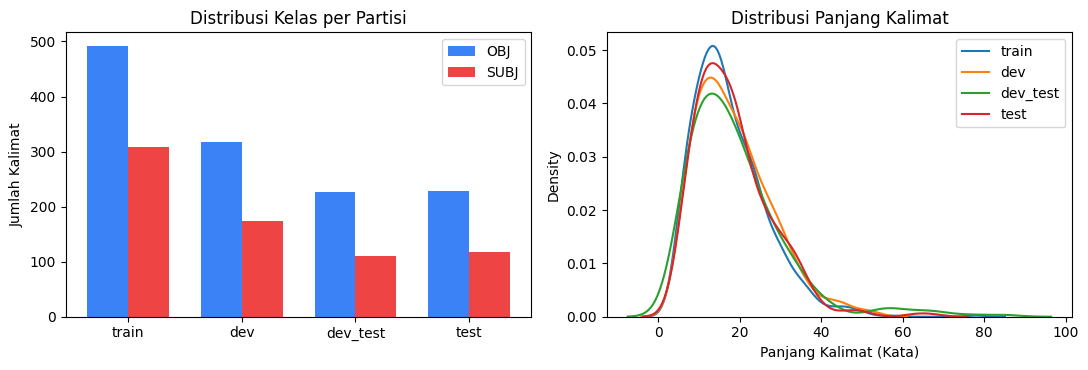

In [2]:
LABEL2ID = {"OBJ": 0, "SUBJ": 1}
ID2LABEL = {0: "OBJ", 1: "SUBJ"}


def load_split(filepath: Path) -> pd.DataFrame:
    """Load a Task 1 TSV split without quote parsing so unbalanced news quotes stay intact."""
    df = pd.read_csv(filepath, sep="\t", quoting=csv.QUOTE_NONE)
    required = {"sentence_id", "sentence", "label"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"Kolom wajib hilang di {filepath.name}: {missing}")
    df = df[["sentence_id", "sentence", "label"]].copy()
    df["sentence"] = df["sentence"].astype(str)
    df["label_id"] = df["label"].map(LABEL2ID)
    if df["label_id"].isna().any():
        raise ValueError(f"Ditemukan label tidak dikenal di {filepath.name}")
    df["label_id"] = df["label_id"].astype(int)
    return df


SPLITS = {
    "train": load_split(DATA_DIR / "train_de.tsv"),
    "dev": load_split(DATA_DIR / "dev_de.tsv"),
    "dev_test": load_split(DATA_DIR / "dev_test_de.tsv"),
    "test": load_split(DATA_DIR / "test_de_labeled.tsv"),
}

summary_rows = []
for split_name, df in SPLITS.items():
    vc = df["label"].value_counts()
    n_obj = int(vc.get("OBJ", 0))
    n_subj = int(vc.get("SUBJ", 0))
    total = len(df)
    summary_rows.append({
        "Split": split_name,
        "OBJ": n_obj,
        "SUBJ": n_subj,
        "Total": total,
        "SUBJ (%)": round(100.0 * n_subj / total, 1),
        "Ratio OBJ:SUBJ": round(n_obj / max(n_subj, 1), 2),
    })

display(pd.DataFrame(summary_rows))

# Class weights derived exclusively from train split to prevent leakage
train_counts = SPLITS["train"]["label_id"].value_counts().sort_index()
CLASS_WEIGHTS = len(SPLITS["train"]) / (2.0 * train_counts.values)
print(f"Class weights -> OBJ (0): {CLASS_WEIGHTS[0]:.4f}, SUBJ (1): {CLASS_WEIGHTS[1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
dist_df = pd.DataFrame(summary_rows)
x_pos = np.arange(len(dist_df))
axes[0].bar(x_pos - 0.18, dist_df["OBJ"], width=0.36, label="OBJ", color="#3b82f6")
axes[0].bar(x_pos + 0.18, dist_df["SUBJ"], width=0.36, label="SUBJ", color="#ef4444")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(dist_df["Split"])
axes[0].set_ylabel("Jumlah Kalimat")
axes[0].set_title("Distribusi Kelas per Partisi")
axes[0].legend()

for split_name, df in SPLITS.items():
    word_lens = df["sentence"].str.split().str.len()
    sns.kdeplot(word_lens, ax=axes[1], label=split_name)
axes[1].set_xlabel("Panjang Kalimat (Kata)")
axes[1].set_title("Distribusi Panjang Kalimat")
axes[1].legend()
plt.tight_layout()
plt.show()

## 2. Pra-pemrosesan Minimal dan Sanitasi Teks Jerman

Sanitasi hanya menghapus spasi ganda serta karakter *whitespace* berlebih dan menstandardisasi variasi tanda petik ke format kutipan Jerman (`„ “`). Huruf kapital, tanda baca, partikel modalitas (*ja, doch, wohl*), dan modus *Konjunktiv* dipertahankan utuh.

In [3]:
def normalize_german_quotes(text: str) -> str:
    """Unwrap CSV-escaped quotes and standardize paired quotes to German („ “)."""
    if text.startswith("\"") and text.endswith("\"") and "\"\"" in text:
        text = text[1:-1]
    if "\"\"" in text:
        text = text.replace("\"\"", "\"")
    if "«" in text and "»" in text and text.count("«") == text.count("»"):
        text = text.replace("«", "„").replace("»", "“")
    elif text.count("\"") >= 2 and text.count("\"") % 2 == 0:
        out = []
        opening = True
        for ch in text:
            if ch == "\"":
                out.append("„" if opening else "“")
                opening = not opening
            else:
                out.append(ch)
        text = "".join(out)
    if text.count("\u201c") == text.count("\u201d") and "\u201d" in text and "\u201e" not in text:
        text = text.replace("\u201c", "„").replace("\u201d", "“")
    return text


def sanitize_german_text(text: str) -> str:
    """Collapse irregular whitespace and normalize quotation marks without altering casing or grammar."""
    cleaned = re.sub(r"\s+", " ", text).strip()
    return normalize_german_quotes(cleaned)


changed_examples = []
for split_name, df in SPLITS.items():
    df["clean_text"] = df["sentence"].apply(sanitize_german_text)
    diff_mask = df["clean_text"] != df["sentence"]
    print(f"{split_name:8s}: {int(diff_mask.sum())} dari {len(df)} kalimat mengalami sanitasi")
    if len(changed_examples) < 3 and diff_mask.any():
        sample = df.loc[diff_mask, ["sentence", "clean_text"]].iloc[0]
        changed_examples.append((split_name, sample["sentence"], sample["clean_text"]))

for split_name, raw, clean in changed_examples:
    print(f"\n[{split_name}] Sebelum: {raw}")
    print(f"[{split_name}] Sesudah: {clean}")

train   : 47 dari 800 kalimat mengalami sanitasi
dev     : 26 dari 491 kalimat mengalami sanitasi
dev_test: 34 dari 337 kalimat mengalami sanitasi
test    : 28 dari 347 kalimat mengalami sanitasi

[train] Sebelum: "Den Beipackzettel des Impfstoffs Janssen® von Johnson & Johnson finden Sie in der ""Zusammenfassung der Merkmale des Arzneimittels"", das die EMA online in 25 Sprachen zur Verfügung stellt, ab Seite 27."
[train] Sesudah: Den Beipackzettel des Impfstoffs Janssen® von Johnson & Johnson finden Sie in der „Zusammenfassung der Merkmale des Arzneimittels“, das die EMA online in 25 Sprachen zur Verfügung stellt, ab Seite 27.

[dev] Sebelum: «Das sollte in Händen geschulten Fachpersonals sein», sagt er.
[dev] Sesudah: „Das sollte in Händen geschulten Fachpersonals sein“, sagt er.

[dev_test] Sebelum: Doch ein Wort ist international verständlich: “Covid-Testkit”.
[dev_test] Sesudah: Doch ein Wort ist international verständlich: „Covid-Testkit“.


## 3. Audit Fertilitas Tokenizer dan Truncation

Mengukur rasio fragmentasi *subword* per kata (*fertility ratio*) serta persentase pemotongan konteks pada batas `max_length = 128` untuk membandingkan tokenizer multibahasa (`G0`) terhadap tokenizer monolingual Jerman (`G1` sampai `G4`).

In [4]:
def audit_tokenizer(hf_id: str, texts: list[str], max_length: int = 128) -> dict:
    """Measure subword fertility ratio and sequence truncation rate at max_length."""
    tok = load_tokenizer(hf_id)
    total_words = 0
    total_subwords = 0
    max_tokens_seen = 0
    truncated = 0

    for text in texts:
        total_words += len(text.split())
        ids = tok.encode(text, add_special_tokens=True)
        n_tok = len(ids)
        total_subwords += max(n_tok - 2, 0)
        if n_tok > max_tokens_seen:
            max_tokens_seen = n_tok
        if n_tok > max_length:
            truncated += 1

    return {
        "Vocab Size": tok.vocab_size,
        "Fertility Ratio": round(total_subwords / max(total_words, 1), 3),
        "Max Tokens": max_tokens_seen,
        "Truncated (>128)": f"{truncated}/{len(texts)} ({100.0 * truncated / len(texts):.2f}%)",
    }


audit_texts = SPLITS["train"]["clean_text"].tolist() + SPLITS["dev"]["clean_text"].tolist()
fertility_rows = []
for code, spec in CFG["models"].items():
    stats = audit_tokenizer(spec["hf_id"], audit_texts, CFG["max_length"])
    fertility_rows.append({"Kode": code, "Model": spec["name"], **stats})

display(pd.DataFrame(fertility_rows))

[transformers] The tokenizer you are loading from 'microsoft/mdeberta-v3-base' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


,Kode,Model,Vocab Size,Fertility Ratio,Max Tokens,Truncated (>128)
0,G0,mDeBERTa-v3-base,250101,1.865,164,1/1291 (0.08%)
1,G1,GBERT-large,31102,1.472,147,1/1291 (0.08%)
2,G2,GottBERT-base,52009,1.409,139,1/1291 (0.08%)
3,G3,GElectra-large,31102,1.472,147,1/1291 (0.08%)
4,G4,GeBERTa-base,50265,1.360,119,0/1291 (0.00%)


## 4. Baseline Resmi Penyelenggara (SBERT + Logistic Regression)

Menjalankan baseline resmi CheckThat! (`paraphrase-multilingual-MiniLM-L12-v2` + `LogisticRegression` dengan `class_weight='balanced'`) pada data Jerman sebagai batas bawah referensi performa.

In [5]:
def compute_metrics_dict(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """Compute official CheckThat! macro and SUBJ-specific metrics."""
    acc = accuracy_score(y_true, y_pred)
    m_p, m_r, m_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    s_p, s_r, s_f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[1], zero_division=0)
    return {
        "macro_f1": float(m_f1),
        "macro_p": float(m_p),
        "macro_r": float(m_r),
        "subj_f1": float(s_f1[0]),
        "subj_p": float(s_p[0]),
        "subj_r": float(s_r[0]),
        "accuracy": float(acc),
    }


def save_prediction_tsv(df: pd.DataFrame, pred_ids: np.ndarray, out_path: Path, include_header: bool = True) -> None:
    """Write predictions in CheckThat! TSV format; scorer/evaluate.py requires the column header."""
    out_df = pd.DataFrame({
        "sentence_id": df["sentence_id"].values,
        "label": [ID2LABEL[int(x)] for x in pred_ids],
    })
    out_df.to_csv(out_path, index=False, header=include_header, sep="\t", quoting=csv.QUOTE_NONE)


sbert_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
X_train_sbert = sbert_model.encode(SPLITS["train"]["clean_text"].tolist(), show_progress_bar=False)
lr_clf = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=CFG["seed"])
lr_clf.fit(X_train_sbert, SPLITS["train"]["label_id"].values)

baseline_results = {}
for split_name in ["dev", "dev_test", "test"]:
    df_split = SPLITS[split_name]
    X_eval = sbert_model.encode(df_split["clean_text"].tolist(), show_progress_bar=False)
    preds = lr_clf.predict(X_eval)
    baseline_results[split_name] = compute_metrics_dict(df_split["label_id"].values, preds)
    if split_name == "test":
        save_prediction_tsv(df_split, preds, OUTPUT_DIR / "preds" / "task1_mono_german_Baseline.tsv")

del sbert_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Baseline SBERT + LR ->", {k: round(v["macro_f1"], 4) for k, v in baseline_results.items()})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Baseline SBERT + LR -> {'dev': 0.6678, 'dev_test': 0.7048, 'test': 0.6879}


## 5. Pelatihan Enkoder Transformer (G0 sampai G4)

Melatih lima arsitektur encoder secara berurutan pada GPU RTX 3050 dengan `Class-Weighted Cross-Entropy`, presisi campuran FP16, laju pembelajaran `2e-5`, *linear warmup* 10%, dan *early stopping* berdasarkan `macro_f1` data validasi.

In [6]:
class SubjectivityDataset(Dataset):
    def __init__(self, texts: list[str], labels: list[int], tokenizer, max_length: int):
        self.encodings = tokenizer(
            texts,
            truncation=True,
            padding=True,
            max_length=max_length,
        )
        self.labels = labels

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx: int) -> dict:
        item = {k: torch.tensor(v[idx], dtype=torch.long) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


class WeightedLossTrainer(Trainer):
    def __init__(self, class_weights: np.ndarray, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = torch.tensor(class_weights, dtype=torch.float32)

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fn = nn.CrossEntropyLoss(weight=self.class_weights.to(logits.device))
        loss = loss_fn(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


def compute_hf_metrics(eval_pred) -> dict:
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return compute_metrics_dict(labels, preds)


def logits_to_subj_probs(logits: np.ndarray) -> np.ndarray:
    """Apply numerically stable softmax and return positive-class (SUBJ) probabilities."""
    shifted = logits - np.max(logits, axis=1, keepdims=True)
    exp_vals = np.exp(shifted)
    probs = exp_vals / np.sum(exp_vals, axis=1, keepdims=True)
    return probs[:, 1]


class BestModelTrackerCallback(TrainerCallback):
    """Track best Macro-F1 weights without saving multi-GB optimizer checkpoints each epoch."""

    def __init__(self, best_path: Path, patience: int):
        self.best_path = best_path
        self.patience = patience
        self.best_score = -1.0
        self.wait = 0

    def on_evaluate(self, args, state, control, model=None, metrics=None, **kwargs):
        score = (metrics or {}).get("eval_macro_f1", -1.0)
        if score > self.best_score:
            self.best_score = score
            self.wait = 0
            self.best_path.parent.mkdir(parents=True, exist_ok=True)
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, self.best_path)
        else:
            self.wait += 1
            if self.wait >= self.patience:
                control.should_training_stop = True


def train_and_extract_probs(code: str, spec: dict) -> dict[str, np.ndarray]:
    """Fine-tune a single encoder checkpoint and save dev, dev_test, and test probabilities."""
    prob_dir = OUTPUT_DIR / "probs"
    expected_files = {s: prob_dir / f"{code}_{s}.npy" for s in ["dev", "dev_test", "test"]}
    if not CFG["force_retrain"] and all(p.exists() for p in expected_files.values()):
        print(f"[{code}] Menggunakan probabilitas tersimpan dari cache.")
        return {s: np.load(p) for s, p in expected_files.items()}

    set_seed(CFG["seed"])
    hf_id = spec["hf_id"]
    print(f"\n[{code}] Memuat & melatih {hf_id} (bs={spec['batch_size']}, accum={spec['grad_accum']})...")

    tokenizer = load_tokenizer(hf_id)
    config = None
    model_cls = AutoModelForSequenceClassification
    local_ready = False
    for local_only in (True, False):
        try:
            config = AutoConfig.from_pretrained(hf_id, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID, local_files_only=local_only)
            local_ready = local_only
            break
        except ValueError:
            try:
                config = BertConfig.from_pretrained(hf_id, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID, local_files_only=local_only)
                model_cls = BertForSequenceClassification
                local_ready = local_only
                break
            except OSError:
                continue
        except OSError:
            continue
    if config is None:
        raise RuntimeError(f"Gagal memuat config untuk {hf_id}")
    for attr in ("classifier_dropout", "cls_dropout", "hidden_dropout_prob"):
        if hasattr(config, attr) and getattr(config, attr) is not None:
            setattr(config, attr, CFG["dropout"])

    try:
        model = model_cls.from_pretrained(hf_id, config=config, local_files_only=local_ready).float()
    except OSError:
        model = model_cls.from_pretrained(hf_id, config=config).float()

    datasets = {
        s: SubjectivityDataset(SPLITS[s]["clean_text"].tolist(), SPLITS[s]["label_id"].tolist(), tokenizer, CFG["max_length"])
        for s in ["train", "dev", "dev_test", "test"]
    }

    steps_per_epoch = max(1, len(datasets["train"]) // (spec["batch_size"] * spec["grad_accum"]))
    warmup_steps = int(CFG["warmup_ratio"] * steps_per_epoch * CFG["epochs"])

    ckpt_dir = OUTPUT_DIR / "checkpoints" / code
    best_weights_path = ckpt_dir / "best_weights.pt"
    tracker = BestModelTrackerCallback(best_weights_path, CFG["patience"])

    training_args = TrainingArguments(
        output_dir=str(ckpt_dir),
        num_train_epochs=CFG["epochs"],
        per_device_train_batch_size=spec["batch_size"],
        per_device_eval_batch_size=32,
        gradient_accumulation_steps=spec["grad_accum"],
        learning_rate=CFG["lr"],
        warmup_steps=warmup_steps,
        weight_decay=CFG["weight_decay"],
        max_grad_norm=1.0,
        bf16=CFG["bf16"],
        fp16=CFG["fp16"],
        eval_strategy="epoch",
        save_strategy="no",
        seed=CFG["seed"],
        logging_steps=25,
        report_to="none",
        dataloader_pin_memory=torch.cuda.is_available(),
    )

    trainer = WeightedLossTrainer(
        class_weights=CLASS_WEIGHTS,
        model=model,
        args=training_args,
        train_dataset=datasets["train"],
        eval_dataset=datasets["dev"],
        processing_class=tokenizer,
        compute_metrics=compute_hf_metrics,
        callbacks=[tracker],
    )

    trainer.train()
    if best_weights_path.exists():
        state = torch.load(best_weights_path, map_location=trainer.args.device, weights_only=True)
        model.load_state_dict(state)
        best_weights_path.unlink(missing_ok=True)

    probs_out = {}
    for split_name in ["dev", "dev_test", "test"]:
        pred_out = trainer.predict(datasets[split_name])
        probs_subj = logits_to_subj_probs(pred_out.predictions)
        np.save(expected_files[split_name], probs_subj)
        probs_out[split_name] = probs_subj

    print(f"[{code}] Best Dev Macro-F1: {tracker.best_score:.4f}")

    # Release GPU allocations explicitly so subsequent large models fit inside 6 GB VRAM
    del model, trainer, datasets
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return probs_out

In [7]:
MODEL_PROBS = {}
for code, spec in CFG["models"].items():
    MODEL_PROBS[code] = train_and_extract_probs(code, spec)

[G0] Menggunakan probabilitas tersimpan dari cache.
[G1] Menggunakan probabilitas tersimpan dari cache.
[G2] Menggunakan probabilitas tersimpan dari cache.
[G3] Menggunakan probabilitas tersimpan dari cache.
[G4] Menggunakan probabilitas tersimpan dari cache.


## 6. Kalibrasi Ambang Batas dan Ensembel Soft-Voting (G5 dan G6)

Menyapu ambang batas keputusan $T \in [0{,}10, 0{,}90]$ dengan langkah $0{,}01$ pada data validasi (`dev_de`) untuk setiap model dan ensembel, mengunci nilai $T^*$ optimal, lalu mengevaluasi partisi `dev_test` dan `test` sekaligus memvalidasi berkas prediksi memakai skrip resmi `scorer/evaluate.py`.

In [8]:
def find_best_threshold(y_true: np.ndarray, probs: np.ndarray) -> tuple[float, float]:
    """Grid search threshold in [0.10, 0.90] to maximize Macro-F1 on the dev set."""
    best_t, best_f1 = 0.50, -1.0
    for t in np.arange(0.10, 0.901, 0.01):
        preds = (probs >= t).astype(int)
        score = compute_metrics_dict(y_true, preds)["macro_f1"]
        if score > best_f1:
            best_f1 = score
            best_t = float(round(t, 2))
    return best_t, best_f1


def run_official_scorer(gold_path: Path, pred_path: Path) -> str:
    """Execute CLEF scorer/evaluate.py to confirm output format compliance and official scores."""
    proc = subprocess.run(
        [sys.executable, str(SCORER_PATH), "-g", str(gold_path), "-p", str(pred_path)],
        capture_output=True,
        text=True,
        check=False,
    )
    return (proc.stdout + "\n" + proc.stderr).strip()


MODEL_PROBS["G5"] = {
    s: (MODEL_PROBS["G1"][s] + MODEL_PROBS["G2"][s] + MODEL_PROBS["G3"][s]) / 3.0
    for s in ["dev", "dev_test", "test"]
}
MODEL_PROBS["G6"] = {
    s: (MODEL_PROBS["G1"][s] + MODEL_PROBS["G2"][s] + MODEL_PROBS["G3"][s] + MODEL_PROBS["G4"][s]) / 4.0
    for s in ["dev", "dev_test", "test"]
}

SYSTEM_NAMES = {
    **{k: v["name"] for k, v in CFG["models"].items()},
    "G5": "Ensemble (G1+G2+G3)",
    "G6": "Ensemble (G1+G2+G3+G4)",
}

eval_rows = [
    {
        "Kode": "Baseline",
        "Model": "SBERT + LR",
        "T*": "-",
        "Dev Macro-F1": round(baseline_results["dev"]["macro_f1"], 4),
        "Dev-Test Macro-F1": round(baseline_results["dev_test"]["macro_f1"], 4),
        "Test Macro-F1": round(baseline_results["test"]["macro_f1"], 4),
        "Test SUBJ-F1": round(baseline_results["test"]["subj_f1"], 4),
        "Test SUBJ-P": round(baseline_results["test"]["subj_p"], 4),
        "Test SUBJ-R": round(baseline_results["test"]["subj_r"], 4),
        "Test Accuracy": round(baseline_results["test"]["accuracy"], 4),
    }
]

CALIBRATED_THRESHOLDS = {}
TEST_PREDICTIONS = {}
y_dev = SPLITS["dev"]["label_id"].values
y_dev_test = SPLITS["dev_test"]["label_id"].values
y_test = SPLITS["test"]["label_id"].values

for code in ["G0", "G1", "G2", "G3", "G4", "G5", "G6"]:
    best_t, dev_f1 = find_best_threshold(y_dev, MODEL_PROBS[code]["dev"])
    CALIBRATED_THRESHOLDS[code] = best_t

    dev_test_preds = (MODEL_PROBS[code]["dev_test"] >= best_t).astype(int)
    test_preds = (MODEL_PROBS[code]["test"] >= best_t).astype(int)
    TEST_PREDICTIONS[code] = test_preds

    m_dt = compute_metrics_dict(y_dev_test, dev_test_preds)
    m_te = compute_metrics_dict(y_test, test_preds)

    pred_file = OUTPUT_DIR / "preds" / f"task1_mono_german_{code}.tsv"
    save_prediction_tsv(SPLITS["test"], test_preds, pred_file, include_header=True)

    eval_rows.append({
        "Kode": code,
        "Model": SYSTEM_NAMES[code],
        "T*": best_t,
        "Dev Macro-F1": round(dev_f1, 4),
        "Dev-Test Macro-F1": round(m_dt["macro_f1"], 4),
        "Test Macro-F1": round(m_te["macro_f1"], 4),
        "Test SUBJ-F1": round(m_te["subj_f1"], 4),
        "Test SUBJ-P": round(m_te["subj_p"], 4),
        "Test SUBJ-R": round(m_te["subj_r"], 4),
        "Test Accuracy": round(m_te["accuracy"], 4),
    })

summary_df = pd.DataFrame(eval_rows)
summary_df.to_csv(OUTPUT_DIR / "summary_results.csv", index=False)
display(summary_df)

print("\nValidasi skor resmi untuk G5 dan G6 via scorer/evaluate.py:")
for code in ["G5", "G6"]:
    out_log = run_official_scorer(DATA_DIR / "test_de_labeled.tsv", OUTPUT_DIR / "preds" / f"task1_mono_german_{code}.tsv")
    print(f"--- {code} ({SYSTEM_NAMES[code]}) ---")
    print(out_log)

,Kode,Model,T*,Dev Macro-F1,Dev-Test Macro-F1,Test Macro-F1,Test SUBJ-F1,Test SUBJ-P,Test SUBJ-R,Test Accuracy
0,Baseline,SBERT + LR,-,0.6678,0.7048,0.6879,0.6070,0.5612,0.6610,0.7089
1,G0,mDeBERTa-v3-base,0.44,0.7860,0.8425,0.7881,0.7117,0.7596,0.6695,0.8156
2,G1,GBERT-large,0.77,0.8145,0.8775,0.8012,0.7336,0.7568,0.7119,0.8242
3,G2,GottBERT-base,0.15,0.7948,0.8277,0.8013,0.7297,0.7788,0.6864,0.8271
4,G3,GElectra-large,0.65,0.8221,0.8650,0.8408,0.7793,0.8737,0.7034,0.8646
5,G4,GeBERTa-base,0.54,0.8105,0.8232,0.7876,0.6995,0.8353,0.6017,0.8242
6,G5,Ensemble (G1+G2+G3),0.34,0.8240,0.8761,0.8265,0.7665,0.7982,0.7373,0.8473
7,G6,Ensemble (G1+G2+G3+G4),0.43,0.8230,0.8661,0.8194,0.7523,0.8200,0.6949,0.8444



Validasi skor resmi untuk G5 dan G6 via scorer/evaluate.py:


--- G5 (Ensemble (G1+G2+G3)) ---
INFO : The file is properly formatted
INFO : Started evaluating results for Task 1...
INFO : 
            macro-F1: 0.8265
            macro-P: 0.8340
            macro-R: 0.8206
            
            SUBJ-F1: 0.7665
            SUBJ-P: 0.7982
            SUBJ-R: 0.7373
            
            accuracy: 0.8473


--- G6 (Ensemble (G1+G2+G3+G4)) ---
INFO : The file is properly formatted
INFO : Started evaluating results for Task 1...
INFO : 
            macro-F1: 0.8194
            macro-P: 0.8371
            macro-R: 0.8082
            
            SUBJ-F1: 0.7523
            SUBJ-P: 0.8200
            SUBJ-R: 0.6949
            
            accuracy: 0.8444


## 7. Visualisasi Perbandingan dan Analisis Kesalahan

Membandingkan capaian `Test Macro-F1` seluruh model terhadap batas bawah resmi (`0,6960`) serta rekor juara bertahan CLEF 2025 SmolLab_SEU (`0,8520`), disertai *confusion matrix* dan inspeksi kesalahan terburuk pada model ensembel.

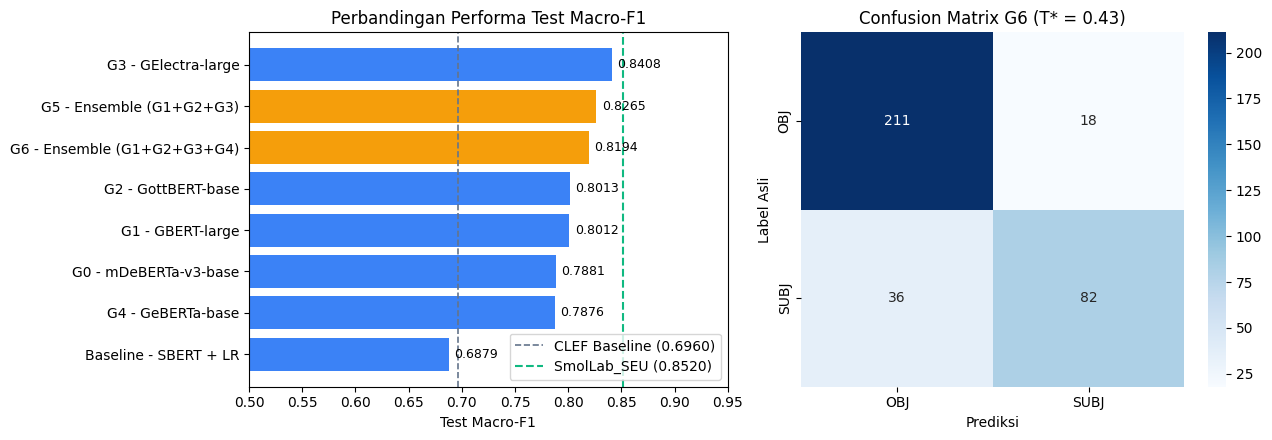

Total kesalahan G6 pada Test Set: 54 dari 347 kalimat


,label,pred_label,prob_SUBJ,clean_text
198,SUBJ,OBJ,0.0010,Das PEI schreibt zu dem „Einzelfall“ lediglich...
88,SUBJ,OBJ,0.0011,In Grossbritannien starben von knapp zehn Mill...
193,SUBJ,OBJ,0.0011,Das Ergebnis einer Studie mit Zellkulturen ist...
47,SUBJ,OBJ,0.0011,Wie aus einer Antwort des Bundesfinanzminister...
286,SUBJ,OBJ,0.0012,In Österreich wurden auf diese Weise zum Beisp...
204,SUBJ,OBJ,0.0012,Dort wird – anders als bei der Staats-Sendeans...
73,SUBJ,OBJ,0.0013,Insgesamt müsste dann folgende Anzahl an Mensc...
256,SUBJ,OBJ,0.0013,"Die meisten sind leicht zu erkennen, andere al..."
19,SUBJ,OBJ,0.0015,Es wird hier auch wieder nur sehr kurz auf den...
131,OBJ,SUBJ,0.9985,Man male ledig­lich das Schreck­ge­spenst der ...


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_df = summary_df.sort_values("Test Macro-F1", ascending=True)
colors = ["#f59e0b" if k in ("G5", "G6") else "#3b82f6" for k in plot_df["Kode"]]
axes[0].barh(plot_df["Kode"] + " - " + plot_df["Model"], plot_df["Test Macro-F1"], color=colors)
axes[0].axvline(0.6960, color="#64748b", linestyle="--", linewidth=1.2, label="CLEF Baseline (0.6960)")
axes[0].axvline(0.8520, color="#10b981", linestyle="--", linewidth=1.5, label="SmolLab_SEU (0.8520)")
axes[0].set_xlim(0.5, 0.95)
axes[0].set_xlabel("Test Macro-F1")
axes[0].set_title("Perbandingan Performa Test Macro-F1")
axes[0].legend(loc="lower right")
for idx, val in enumerate(plot_df["Test Macro-F1"]):
    axes[0].text(val + 0.005, idx, f"{val:.4f}", va="center", fontsize=9)

cm = confusion_matrix(y_test, TEST_PREDICTIONS["G6"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["OBJ", "SUBJ"], yticklabels=["OBJ", "SUBJ"], ax=axes[1])
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Label Asli")
axes[1].set_title(f"Confusion Matrix G6 (T* = {CALIBRATED_THRESHOLDS['G6']})")

plt.tight_layout()
plt.show()

err_df = SPLITS["test"][["sentence_id", "clean_text", "label", "label_id"]].copy()
err_df["prob_SUBJ"] = np.round(MODEL_PROBS["G6"]["test"], 4)
err_df["pred_label"] = [ID2LABEL[int(x)] for x in TEST_PREDICTIONS["G6"]]
err_df["error_confidence"] = np.abs(err_df["prob_SUBJ"] - err_df["label_id"])
misclassified = err_df[err_df["label"] != err_df["pred_label"]].sort_values("error_confidence", ascending=False)

print(f"Total kesalahan G6 pada Test Set: {len(misclassified)} dari {len(err_df)} kalimat")
display(misclassified[["label", "pred_label", "prob_SUBJ", "clean_text"]].head(10))